Restarted .venv01 (3.13.11) (Python 3.13.11)

In [ ]:
# SEARCH WORDS :
# FINAL_READY_OUTPUTS_BY_YEAR
# YEARLY_TCN_ESTIMATION
# YEARLY_MFIV_GARCH_ESTIMATION
# TESTING_MAIN_WITH_CACHE
# TCN_SCORE_CALIBRATION_DIAGNOSTIC
## TCN_SCORE_THRESHOLD_CALIBRATION
### TCN_SCORE_THRESHOLD_TRADER_CALIBRATION
import pandas as pd
import numpy as np
from math import sqrt, pi, exp
from arch import arch_model
import yfinance as yf 
from scipy.optimize import minimize
import warnings
from arch.__future__ import reindexing
from arch.utility.exceptions import ConvergenceWarning
# from srcA.msGarch import msGARCH
# from srcA.metrics import metrics
# from srcA.msGarch import msGARCHIV
from tqdm import tqdm

from xgboost import XGBRegressor
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="y is poorly scaled")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)


import os, sys
sys.path.insert(0, "/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.path.insert(0, "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/MFIV_calibration")
os.chdir("/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.modules.pop("srcB", None)

### NOTE :
# # COMES FROM MODELLING.ipynb
import pickle 
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_01.pkl", "rb") as f:
    outputs_by_year = pickle.load(f)


# IMPORTS FROM SRC
from srcB.market import *
from srcB.trader_testing_tcn_v1 import testing_execute_trading_strategy
from srcB.helpers import *

# READ D_BTC AND DF
from pathlib import Path
DATA_DIR = Path("../data/rawData")
YEARS = [2019, 2020, 2021]
d_btc_raw_by_year = {}
df_raw_by_year = {}
for y in YEARS:
    d_btc_raw_by_year[y] = pd.read_parquet(DATA_DIR / f"btc_underlying_minutely_{y}.parquet")
    df_raw_by_year[y]    = pd.read_parquet(DATA_DIR / f"derivative_data_{y}.parquet")

# SET INDEX TO DATETIME
for y in YEARS:
    d_btc_raw_by_year[y] = d_btc_raw_by_year[y].set_index(pd.to_datetime(d_btc_raw_by_year[y]["date_time"]))
    df_raw_by_year[y] = df_raw_by_year[y].set_index(pd.to_datetime(df_raw_by_year[y]["date_time"]))


# ==================================================================================================================
# ======================================= LOAD XQ_BY_YEAR USING X_BY_YEAR ==========================================
# ==================================================================================================================

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/x_by_year_fut/x_by_year.pkl", "rb") as f:
    X_by_year = pd.read_pickle(f)

YEARS = [2019, 2020, 2021]
QUARTERS = ["q1", "q2", "q3", "q4"]

for y in YEARS:
    X_by_year[y] = X_by_year[y].copy()
    X_by_year[y]["rv"] = X_by_year[y]["rt"] ** 2

Xq_by_year = {}

for y in YEARS:
    Xq_by_year[y] = {}

    Xq_by_year[y]["q1"] = X_by_year[y].loc[f"{y}-01-01" : f"{y}-03-31 23:59:59"].copy()

    Xq_by_year[y]["q2"] = X_by_year[y].loc[f"{y}-04-01" : f"{y}-06-30 23:59:59"].copy()

    Xq_by_year[y]["q3"] = X_by_year[y].loc[f"{y}-07-01" : f"{y}-09-30 23:59:59"].copy()

    Xq_by_year[y]["q4"] = X_by_year[y].loc[f"{y}-10-01" : f"{y}-12-31 23:59:59"].copy()


# ==================================================================================================================
# ======================================= MFIV SCALING =============================================================
# ================== CONVERT ANNUALIZED MFIV -> CUMULATIVE H-HOUR DECIMAL VARIANCE ===============================
# ==================================================================================================================

MFIVS = list(range(2, 577))
for y in YEARS:
    for q in QUARTERS:
        for H in MFIVS:
            Xq_by_year[y][q][f"MFIV_{H}"] *= H / 8760.0


# ==================================================================================================================
# ============================================= BORROW RFR COLUMN  =================================================
# ==================================================================================================================
import pickle
with open ("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/ready_data/d_btc_by_year_all.pkl", "rb") as f :
    d_btc_by_year = pickle.load(f)

YEARS = [2019, 2020, 2021]
for y in YEARS:
    d_btc_raw_by_year[y]["rfr"] = d_btc_by_year[y]["rfr"].reindex(d_btc_raw_by_year[y].index, method="ffill")

# =============================================================================================================
# ======================================= CHECKPOINT 1. RUN UNTIL HERE ========================================
# =============================================================================================================

TCN bundles saved: [2019, 2020, 2021]
2021 tcn_mfiv
161
[{'time': Timestamp('2021-01-13 01:00:00+0000', tz='UTC'), 'tcn_action': 'short_straddle', 'tcn_best_score': 0.0038653244264423847, 'signal': nan, 'q_lo': nan, 'selected_calls': [<srcB.market.Instrument object at 0x1601907a0>], 'selected_puts': [<srcB.market.Instrument object at 0x1461697f0>], 'call_ivs': [150.96], 'put_ivs': [140.87], 'spot': 32649.5, 'rfr': 0.0008997975607295042, 'call_greeks': [{'delta': -0.4788514638856973, 'gamma': np.float64(-5.159334227871373e-05)}], 'put_greeks': [{'delta': 0.5291799409622651, 'gamma': np.float64(-5.521842803147424e-05)}], 'entry_equity': np.float64(100896.60527700516)}]
buy_to_close         344
sell_to_close        243
sell_to_open         182
buy_to_open          140
expiry_settlement      5
Name: count, dtype: int64
outputs: True
cache: True
   year     model    sharpe
0  2019  tcn_mfiv  0.664813
1  2020  tcn_mfiv  1.257190
2  2021  tcn_mfiv  0.386731


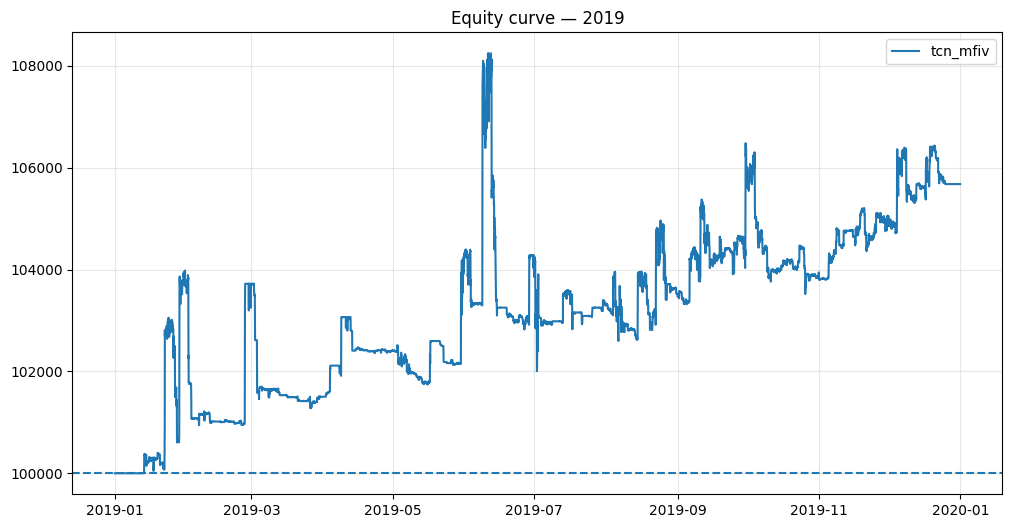

In [ ]:
# # =============================== LOAD OPTIMAL PARAMETERS IN hyperparam_tuning.py ==================================
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/hyperparameters/tcn_best_params.pkl", "rb") as f:
    best_tcn_params = pickle.load(f)

FORWARD_HOURS = 96
# # ======================================= YEARLY_TCN_ESTIMATION  ===================================================
# # ==================================================================================================================
sys.modules.pop("srcB.tcn_model_mfiv", None)
from srcB.tcn_model_mfiv import *

YEARS = [2019, 2020, 2021]
QUARTERS = ["q1", "q2", "q3", "q4"]
tcn_bundle_by_year = {}
tcn_targets_by_year = {}
tcn_output_by_year = {}

for y in YEARS:
    X_df = pd.concat([
        Xq_by_year[y][q]
        for q in QUARTERS
    ]).sort_index().copy()

    garch_df = pd.concat([
        outputs_by_year[y][q]["garch"]
        for q in QUARTERS
    ]).sort_index()

    X_df["garch"] = garch_df.reindex(X_df.index)

    tcn_output, tcn_bundle, tcn_targets = tcn_mfiv(
        X_df=X_df,
        option_df=df_raw_by_year[y],
        time_df=d_btc_raw_by_year[y],
        sequence_length=168,
        forward_hours=FORWARD_HOURS,
        delta_target=0.20,
        channels=best_tcn_params["channels"],
        kernel_size=best_tcn_params["kernel_size"],
        dropout=best_tcn_params["dropout"],
        epochs=best_tcn_params["epochs_by_year"][y],
        batch_size=best_tcn_params["batch_size"],
        learning_rate=best_tcn_params["learning_rate"],
        weight_decay=best_tcn_params["weight_decay"]
    )
    tcn_output_by_year[y] = tcn_output
    tcn_bundle_by_year[y] = tcn_bundle
    tcn_targets_by_year[y] = tcn_targets

    for q in QUARTERS:
        q_index = Xq_by_year[y][q].index
        tcn_q = tcn_output.reindex(q_index)
        outputs_by_year[y][q] = pd.concat( [outputs_by_year[y][q], tcn_q], axis=1 )

# tcn_q adds exactly the below columns to outputs_by_year, later saved as outputs_by_year_04
# [
#     "tcn_long_straddle",
#     "tcn_short_straddle",
#     "tcn_long_strangle",
#     "tcn_short_strangle",
#     "tcn_best_score",
#     "tcn_action"
# ]

# =============================================================================================================
# ======================================= SAVE TCN BUNDLES ====================================================
# =============================================================================================================
os.makedirs("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/TCN", exist_ok = True)
import pickle
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/TCN/tcn_bundle_by_year.pkl", "wb") as f:
    pickle.dump(tcn_bundle_by_year, f)

print("TCN bundles saved:", list(tcn_bundle_by_year.keys()))

# # ==================================================================================================================
# SAVE THIS OUTPUTS
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_04.pkl", "wb") as f:
    pickle.dump(outputs_by_year, f)
## ==================================================================================================================





# # =============================================================================================================
# # ======================================= CHECKPOINT 2. RUN FROM HERE ==================================================================================================
# # =============================================================================================================

# import pickle
# with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_04.pkl", "rb") as f:
#     outputs_by_year = pickle.load(f)

# # IMPORTS FROM SRC
from srcB.market import *
from srcB.trader_testing_tcn_v1 import testing_execute_trading_strategy
from srcB.helpers import *

# ==================================================================================================================
# ======================================= PREPARE TRADER INPUT ======================================================
# ==================================================================================================================

for y in YEARS:
    for q in QUARTERS:
        outputs_by_year[y][q]["rv"] = Xq_by_year[y][q]["rv"].reindex(
            outputs_by_year[y][q].index
        )
        outputs_by_year[y][q]["MFIV_24"] = Xq_by_year[y][q]["MFIV_24"].reindex(
            outputs_by_year[y][q].index
        )

# ==================================================================================================================
# ======================================= CACHE FOR WARMUP ==========================================================
# ==================================================================================================================
CACHE_YEARS = [2019, 2020, 2021]
RUN_BY = "year"
if RUN_BY == "year":
    trader_cache = {
        y: pd.concat(
            [
                outputs_by_year[yy][q]
                for yy in CACHE_YEARS
                if yy <= y
                for q in QUARTERS
            ]
        ).sort_index()
        for y in CACHE_YEARS
    }

elif RUN_BY == "quarter":
    trader_cache = {
        (y, q): pd.concat(
            [
                outputs_by_year[yy][qq]
                for yy in CACHE_YEARS
                for qq in QUARTERS
                if (
                    yy < y
                    or (yy == y and QUARTERS.index(qq) <= QUARTERS.index(q))
                )
            ]
        ).sort_index()
        for y in CACHE_YEARS
        for q in QUARTERS
    }
if RUN_BY == "year":
    PERIODS = YEARS
else:
    PERIODS = [(y, q) for y in YEARS for q in QUARTERS]
    

# ==================================================================================================================
# ======================================= TESTING_MAIN_WITH_CACHE  ==========================================================
# ==================================================================================================================
# sys.modules.pop("srcB", None)

sys.modules.pop("srcB.trader_testing_tcn_v1", None)
from srcB.trader_testing_tcn_v1 import testing_execute_trading_strategy
YEARS = [2019, 2020, 2021]
MODELS = [
    "tcn_mfiv"
]
RUN_BY = "year"
strategy_results = {}
for YEAR in YEARS:
    for MODEL in MODELS:
        market = Market(
            option_df=df_raw_by_year[YEAR],
            time_df=d_btc_raw_by_year[YEAR],
            starting_cash=100_000,
            im_multiplier=0.15,
            mm_buffer_rate=0.05,
        )
        greek_tests = []
        yearly_snapshots = []
        if RUN_BY == "year":
            periods = [None]
        else:
            periods = ["q1", "q2", "q3", "q4"]
            
        for q in periods:
            snapshots, greek_tests_q = testing_execute_trading_strategy(
                bt_year=YEAR,
                bt_quarter=q,
                model=MODEL,
                outputs_by_year=outputs_by_year,
                market=market,
                trader_cache=trader_cache,
                run_by=RUN_BY,
                quantity=10,
                expiry_days=30,
                hold_days=7,
                lookback_hours=168,
                mean_hours=12,
                ql=0.10,
                qh=0.90,
                z=1.645,
                forward_hours=FORWARD_HOURS
            )

            greek_tests.extend(greek_tests_q)
            yearly_snapshots.extend(snapshots)
        history_key = f"{MODEL}_{str(YEAR)[2:]}"
        equity_curve = market.get_equity_history()
        strategy_results[history_key] = {
            "equity_curve": equity_curve,
            "snapshots": yearly_snapshots,
            "greek_tests": greek_tests,
            "orders": list(market.orders),
            "transactions": list(market.transactions),
            "final_cash": market.cash,
            "required_margin": market.get_total_required_margin(),
            "free_liquidity": market.get_free_liquidity(),
        }
print(YEAR, MODEL)

# ==================================================================================================================
print(len(greek_tests))
print(greek_tests[:1])
print(pd.Series([x["action"] for x in market.transactions]).value_counts())
print("outputs:", "tcn_action" in outputs_by_year[2019]["q1"].columns)
print("cache:", "tcn_action" in trader_cache[2019].columns)
[c for c in trader_cache[2019].columns if c.startswith("tcn")]

# ==================================================================================================================
# ============================================= SAVE DICT  ========================================================
# ==================================================================================================================
import sys, os
os.makedirs("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/data_strategy_results", exist_ok = True)
import pickle 
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/data_strategy_results/strategy_results.pkl", "wb") as f:
    pickle.dump(strategy_results, f)

# # LOAD BACK 
# with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/data_strategy_results/strategy_results.pkl", "rb") as f:
#     strategy_results = pickle.load(f)

## ==================================================================================================================
## ============================================= SHARPEE  ===========================================================
## ==================================================================================================================
YEARS = [2019, 2020, 2021]
MODELS = ["tcn_mfiv"]
rows = []

for y in YEARS:
    for model in MODELS:

        history_key = f"{model}_{str(y)[2:]}"
        snapshots = strategy_results[history_key]["snapshots"]

        equity = pd.Series( [s["equity"] for s in snapshots], index=[s["time"] for s in snapshots] )

        returns = equity.pct_change().dropna()
        sharpe = returns.mean() / returns.std() * np.sqrt(24 * 365)

        rows.append({ "year": y, "model": model, "sharpe": sharpe })

sharpe_table = pd.DataFrame(rows)

print(sharpe_table)


# ==================================================================================================================
# ============================================= PLOT EQUITY  =======================================================
# ==================================================================================================================
import matplotlib.pyplot as plt
# MODELS = ["garch", "garch_mfiv", "garch_n_mfiv", "garch_mfiv_avg", "regime_switching_mfiv"]
MODELS = ["tcn_mfiv"]
PLOT_YEAR = 2019
plt.figure(figsize=(12, 6))
for MODEL in MODELS:
    plot_key = f"{MODEL}_{str(PLOT_YEAR)[2:]}"
    result = strategy_results[plot_key]
    eq = pd.DataFrame(result["snapshots"]).drop_duplicates("time").sort_values("time")
    plt.plot(eq["time"], eq["equity"], label=MODEL)
plt.axhline(100_000, linestyle="--")
plt.title(f"Equity curve — {PLOT_YEAR}")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [ ]:
# # ============================================= PHASE 2 =====================================================
# # ======================================= DIAGNOSTICS FOR TCN ===============================================
# # ===========================================================================================================
## 1=============================================================================================================
## ============================== TCN FITTED TARGET-SPACE PERFORMANCE ==========================================
## =============================================================================================================

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]
rows = []
for y in YEARS:
    test = pd.concat([
        tcn_output_by_year[y][["tcn_action"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort = False).dropna()
    realized = pd.Series(0.0, index=test.index)
    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        mask = test["tcn_action"] == action
        realized.loc[mask] = test.loc[mask, f"target_{action}"]
    sharpe = realized.mean() / realized.std()
    rows.append({
        "year": y,
        "n": len(realized),
        "mean_target": realized.mean(),
        "target_sharpe": sharpe,
        "profitable": (realized > 0).mean()
    })
target_sharpe = pd.DataFrame(rows)
print(target_sharpe)

## ============================== TCN FITTED TARGET-SPACE PERFORMANCE ==========================================

# 2=========================== REQUIRES STRATEGY_RESULTS =======================================================
# =========================== TCN TARGET PERFORMANCE: EXECUTED VS SKIPPED =====================================
# =============================================================================================================

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]

rows = []

for y in YEARS:

    test = pd.concat([
        tcn_output_by_year[y][["tcn_action"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    test = test[test["tcn_action"] != "no_trade"].copy()

    test["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["tcn_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]

    entries = pd.DataFrame(strategy_results[f"tcn_mfiv_{str(y)[2:]}"]["greek_tests"])
    entries["time"] = pd.to_datetime(entries["time"], utc=True).dt.floor("h")
    entries = entries.drop_duplicates("time")
    covered = entries[entries["time"].isin(test.index)].copy()

    predicted = test["tcn_action"].reindex(covered["time"]).to_numpy()
    action_match = (predicted == covered["tcn_action"].to_numpy()).mean()

    executed = test[test.index.isin(covered["time"])]
    skipped = test[~test.index.isin(covered["time"])]

    rows.append({
        "year": y,
        "signals": len(test),
        "successful_entries": len(entries),
        "entries_with_target": len(covered),
        "target_coverage": len(covered) / len(entries),
        "action_match": action_match,
        "all_sharpe": test["target_pnl"].mean() / test["target_pnl"].std(),
        "executed_sharpe": executed["target_pnl"].mean() / executed["target_pnl"].std(),
        "skipped_sharpe": skipped["target_pnl"].mean() / skipped["target_pnl"].std()
    })

execution_check = pd.DataFrame(rows)

print(execution_check)

# 3========Are higher-score bins better? ==============
# ============================= TCN_SCORE_CALIBRATION_DIAGNOSTIC ========================================
# =============================================================================================================
rows = []
for y in YEARS:
    test = pd.concat([
        tcn_output_by_year[y][["tcn_action", "tcn_best_score"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    test = test[test["tcn_action"] != "no_trade"].copy()
    test["target_pnl"] = 0.0
    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["tcn_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]
        
    test["score_bin"] = pd.qcut(
        test["tcn_best_score"],
        5,
        labels=False,
        duplicates="drop"
    )

    x = (
        test.groupby("score_bin")
        .agg(
            n=("target_pnl", "size"),
            mean_score=("tcn_best_score", "mean"),
            mean_target=("target_pnl", "mean"),
            sharpe=("target_pnl", lambda z: z.mean() / z.std()),
            profitable=("target_pnl", lambda z: (z > 0).mean())
        )
        .reset_index()
    )

    x["year"] = y
    rows.append(x)

score_check = pd.concat(rows, ignore_index=True)

print(score_check[[
    "year", "score_bin", "n", "mean_score",
    "mean_target", "sharpe", "profitable"
]].to_string(index=False))

# #4 ===If I only retain signals with tcn_best_score >= threshold, does target-space performance improve? ========
# # ================================= TCN_SCORE_THRESHOLD_CALIBRATION ===========================================
# # =============================================================================================================

tests = {}

for y in YEARS:

    x = pd.concat([
        tcn_output_by_year[y][["tcn_action", "tcn_best_score"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    x = x[x["tcn_action"] != "no_trade"].copy()
    x["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = x["tcn_action"] == action
        x.loc[m, "target_pnl"] = x.loc[m, f"target_{action}"]

    tests[y] = x


scores_all = pd.concat([tests[y]["tcn_best_score"] for y in YEARS])

rows = []

for q in [0, .20, .40, .50, .60, .70, .80, .85, .90]:

    threshold = scores_all.quantile(q)

    for y in YEARS:

        x = tests[y][tests[y]["tcn_best_score"] >= threshold]
        sharpe = x["target_pnl"].mean() / x["target_pnl"].std()

        rows.append({
            "quantile": q,
            "threshold": threshold,
            "year": y,
            "n": len(x),
            "mean_target": x["target_pnl"].mean(),
            "sharpe": sharpe
        })

threshold_check = pd.DataFrame(rows)

print(threshold_check.to_string(index=False))

   year     n  mean_target  target_sharpe  profitable
0  2019  1528    -0.000345      -0.065408    0.560209
1  2020  2984     0.000757       0.150055    0.426273
2  2021  3919     0.000396       0.101746    0.533810
   year  signals  successful_entries  entries_with_target  target_coverage  \
0  2019     1416                 121                   56         0.462810   
1  2020     2833                 186                  102         0.548387   
2  2021     3567                 161                  104         0.645963   

   action_match  all_sharpe  executed_sharpe  skipped_sharpe  
0           1.0   -0.067955        -0.104286       -0.066295  
1           1.0    0.154093         0.223704        0.152512  
2           1.0    0.106702         0.085776        0.107310  
 year  score_bin   n  mean_score  mean_target    sharpe  profitable
 2019          0 284    0.000199    -0.000712 -0.108408    0.605634
 2019          1 283    0.000473    -0.000499 -0.089629    0.618375
 2019          

In [ ]:
# 5===== Does the threshold improvement survive the actual sequential trader? =====
# ================================ TCN_SCORE_THRESHOLD_TRADER_CALIBRATION =====================================
# =============================================================================================================

sys.modules.pop("srcB.trader_testing_tcn_v1", None)
from srcB.trader_testing_tcn_v1 import testing_execute_trading_strategy

THRESHOLDS = [
    0.0,
    float(scores_all.quantile(.70)),
    float(scores_all.quantile(.80)),
    float(scores_all.quantile(.85)),
    float(scores_all.quantile(.90))
]
rows = []

for threshold in THRESHOLDS:
    for y in YEARS:

        market = Market(
            option_df=df_raw_by_year[y],
            time_df=d_btc_raw_by_year[y],
            starting_cash=100_000,
            im_multiplier=0.15,
            mm_buffer_rate=0.05,
        )

        snapshots, greek_tests = testing_execute_trading_strategy(
            bt_year=y,
            bt_quarter=None,
            model="tcn_mfiv",
            outputs_by_year=outputs_by_year,
            market=market,
            trader_cache=trader_cache,
            run_by="year",
            tcn_score_threshold=threshold,
            forward_hours=FORWARD_HOURS
        )

        equity = pd.Series(
            [s["equity"] for s in snapshots],
            index=[s["time"] for s in snapshots]
        )

        returns = equity.pct_change().dropna()
        sharpe = returns.mean() / returns.std() * np.sqrt(24 * 365)

        rows.append({
            "threshold": threshold,
            "year": y,
            "trades": len(greek_tests),
            "sharpe": sharpe
        })

threshold_trader_check = pd.DataFrame(rows)

print(threshold_trader_check.to_string(index=False))

 threshold  year  trades    sharpe
  0.000000  2019     121  0.664813
  0.000000  2020     186  1.257190
  0.000000  2021     161  0.386731
  0.001036  2019      81 -0.204969
  0.001036  2020      96  0.776858
  0.001036  2021     117  0.023895
  0.001320  2019      65 -0.308351
  0.001320  2020      75  0.991031
  0.001320  2021      76  0.346573
  0.001525  2019      53  0.346984
  0.001525  2020      66  0.879437
  0.001525  2021      58  0.390847
  0.001823  2019      43  0.699361
  0.001823  2020      50  0.624197
  0.001823  2021      38  0.172698
